<a href="https://colab.research.google.com/github/PADelucchi/Estudio-Mkt-Argentino-Agua-Oxigenada/blob/main/Evoluci%C3%B3n%20Mkt_Perox.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Trabajo Práctico: Aplicación de Herramientas hasta Unidad 4 (Python, G.Colab,GitHub) sin aplicar Power BI

Nombre y Apellido: Pablo Delucchi

Curso: Herramientas básicas para Análisis de Datos

Fecha de entrega: 13-10-2026

# **Análisis del mercado argentino de peróxido de hidrógeno (2021-2026)**                                           

 Descripción general: El consumo de agua oxigenada tiene múltiples aplicaciones además del uso más conocido en farmacia. Está directamente ligado al crecimiento de diversas industrias, especialmente la del papel, textil, minería y envasado de alimentos.

Siendo uno de los mayores fabricantes de este insumo,es primordial monitorear nuestra posición en el mercado analizando periódicamente las importaciones de la posición arancelaria correspondiente.                                                                  
Objetivos principales: Hacer el seguimiento a lo largo de los últimos 5 años de los siguientes indicadores
1) Evolución del tamaño del mercado en toneladas
2) Participación de mercado por empresa importadora
3) Evolución de los precios
4) Incidencia del costo logístico en el precio del producto
5) Comparar los precios propios frente a los de la competencia
6) Predecir tendencias sobre la futura evolución del mecado en relación a tamaño, precios y participación de los distintos proveedores

Fuente de datos: Obtenidas de estadísticas aduaneras públicas. Nombre Archivo: H2O2 2021-Ago 2026.xlsx
Herramientas utilizadas: entorno Google Colab, Python, pandas, matplotlib, plotly, GitHub



#**Evaluación de viabilidad del análisis de los datos**

Las columnas Importer, Net Weight, Origin country, Freight, Date e Insurance, mediante cálculos que se harán a continuación permiten responder las 6 preguntas que están incluídas en los objetivos del análisis.



#**Carga del dataset y prospección inicial**

In [ ]:
#Importacion de librerias
import pandas as pd
import numpy as np


In [ ]:
# Importamos drive para acceder al dataset
from google.colab import drive
drive.mount('/content/drive')

# Apuntamos a la ruta del archivo correcto en tu Google Drive
ruta_archivo = "/content/drive/MyDrive/HB- AD UTN/H2O2 2021- Ago 2026.xlsx"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Estudio preliminar de datos

df = pd.read_excel(ruta_archivo)
print(df.shape)
print(df.dtypes)

(5792, 36)
Identifier                           object
Item                                  int64
Date                         datetime64[ns]
Datatype                             object
NCM-SIM                              object
Importer                             object
Location                             object
Destination                          object
Customs                              object
Via Transporte                       object
Origin Country                       object
Departure Country                    object
U$S Unit                            float64
U$S FOB                             float64
Freight U$S                         float64
Insurance U$S                       float64
U$S CIF                             float64
Stat. Quant.                        float64
Stat. Unit of Measurement            object
Quantity                            float64
Unit of Measurement                  object
Net Weight                          float64
Gross Weight         

/usr/local/lib/python3.13/dist-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


In [ ]:
print("Filas duplicadas", (df.duplicated().sum()))

Filas duplicadas 0


In [ ]:
# Valores nulos en columnas específicas

nulos = (df['Net Weight'] == 0).sum()
print(f"Cantidad de filas con valor cero en 'Net Weight': {nulos}")

Cantidad de filas con valor cero en 'Net Weight': 166


In [ ]:
# Columnas sin utilidad (varianza nula)
unicos= df.nunique()
columnas_varianza_nula = unicos[unicos<= 1].index.tolist()
print(columnas_varianza_nula)

['Datatype', 'NCM-SIM', 'Right', '% Dere.', 'ALADI Agreement', 'Descripcion Arancelaria', 'Model']


In [ ]:
# Chequeo metadatos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5792 entries, 0 to 5791
Data columns (total 36 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Identifier                 5792 non-null   object        
 1   Item                       5792 non-null   int64         
 2   Date                       5792 non-null   datetime64[ns]
 3   Datatype                   5792 non-null   object        
 4   NCM-SIM                    5792 non-null   object        
 5   Importer                   5792 non-null   object        
 6   Location                   5792 non-null   object        
 7   Destination                5792 non-null   object        
 8   Customs                    5792 non-null   object        
 9   Via Transporte             5792 non-null   object        
 10  Origin Country             5792 non-null   object        
 11  Departure Country          5792 non-null   object        
 12  U$S Un

Hasta aquí se analizó en forma preliminar los datos originales.
Ahora se procederá a crear/definir nuevas columnas, que son cálculos de las ya existentes, necesarias para el análisis de datos

Nuevas columnas:
Precio CIF Unitario (USD/tn)
Freight (USD/tn)

In [ ]:
# Para calcular el precio unitario correcto usando las columnas existentes:
# Colocamos los nombres de las columnas siempre entre comillas dentro de los corchetes
df['Precio CIF USD/tn'] = df['U$S CIF'] / df['Net Weight']

print(df['Precio CIF USD/tn'])

0       0.518605
1       0.534160
2       0.632642
3       0.646400
4       0.518760
          ...   
5787         NaN
5788    0.625000
5789    0.704200
5790    0.755000
5791    0.460800
Name: Precio CIF USD/tn, Length: 5792, dtype: float64


In [ ]:
# Contamos los valores nulos en la nueva columna de precio unitario
nulos = df['Precio CIF USD/tn'].isna().sum()
print(f"Valores nulos en Precio CIF USD/tn: {nulos}")

Valores nulos en Precio CIF USD/tn: 166


In [ ]:
# Para calcular la incidencia del costo logístico en el precio del producto creamos la columna Freight/tn
df['Freight USD/tn'] = df['Freight U$S'] / df['Net Weight']

print(df['Freight USD/tn'])

0       0.125000
1       0.127610
2       0.225185
3       0.147490
4       0.182640
          ...   
5787         NaN
5788    0.127510
5789    0.131070
5790    0.130680
5791    0.155670
Name: Freight USD/tn, Length: 5792, dtype: float64


In [ ]:
# Contamos los valores nulos en la nueva columna Freigth USD/tn
nulos = df['Freight USD/tn'].isna().sum()
print(f"Valores nulos en Freight USD/tn: {nulos}")

Valores nulos en Freight USD/tn: 166


**Criterio adicional de limpieza/clasificación correcta de los datos**

Por conocimiento de las aplicaciones, se sabe que los laboratorios farmacéuticos importan muestras de agua oxigenada y como vienen por via aérea tienen precios muy altos, son cantidades que "ensucian" el análisis.
Se procederá a identificar estos datos, filtrandolos por precio y cantidad

In [ ]:
# Definimos el valor límite para el filtro por precio
valor_limite = 1.1

# Filtramos las filas donde 'Precio CIF USD/tn' sea mayor que el límite
df_filtrado_mayor = df[df['Precio CIF USD/tn'] > valor_limite]

# Mostramos los resultados
print(f"Filas totales: {df.shape[0]}")
print(f"Filas con Precio CIF USD/tn mayor a {valor_limite}: {df_filtrado_mayor.shape[0]}")


Filas totales: 5792
Filas con Precio CIF USD/tn mayor a 1.1: 367


In [ ]:
# Definimos el valor límite para el fitrado por cantidad
valor_limite = 1000

# Filtramos las filas donde 'Net Weight' sea mayor que el límite
df_filtrado_mayor = df[df['Net Weight'] < valor_limite]

# Mostramos los resultados
print(f"Filas totales: {df.shape[0]}")
print(f"Filas con Net Weight mayor a {valor_limite}: {df_filtrado_mayor.shape[0]}")



Filas totales: 5792
Filas con Net Weight mayor a 1000: 367


In [ ]:
# Sobrescribimos df conservando únicamente las filas donde el Precio CIF USD/tn no sea cero
df = df[df['Precio CIF USD/tn'] != 0].dropna(subset=['Precio CIF USD/tn'])

# Verificamos la nueva cantidad de filas
print(f"Nueva cantidad de filas en df: {df.shape[0]}")

Nueva cantidad de filas en df: 5626


DUDA: Luego de este paso, estoy trabajando sobre el archivo original o ya Python trabaja sobre un nvo archivo con 5626 filas???

In [ ]:
# Sobreescribimos df quitando las filas con precios y cantidades anómalas
df = df[df['Precio CIF USD/tn'] <= 1.1]
df = df[df['Net Weight'] >= 1000]

# Verificamos la nueva cantidad de filas
print(f"Nueva cantidad de filas en df: {df.shape[0]}")

Nueva cantidad de filas en df: 5258


Misma duda, ya Python trabaja con 5258 filas, y el dataset original permanece inalterado?



---

**Hasta aquí la limpieza y ordenamiento de los datos **

**Confección de gráficos que respondan las 6 preguntas objetivo descriptas al inicio**

In [ ]:
#Importación de librerias para graficar
import matplotlib.pyplot as plt
import seaborn as sns
import plotly as plt

#Análisis de la evolución en el tiempo del mercado argentino de peróxido de hidrógeno segmentado por importador (Preguntas 1 y 2)

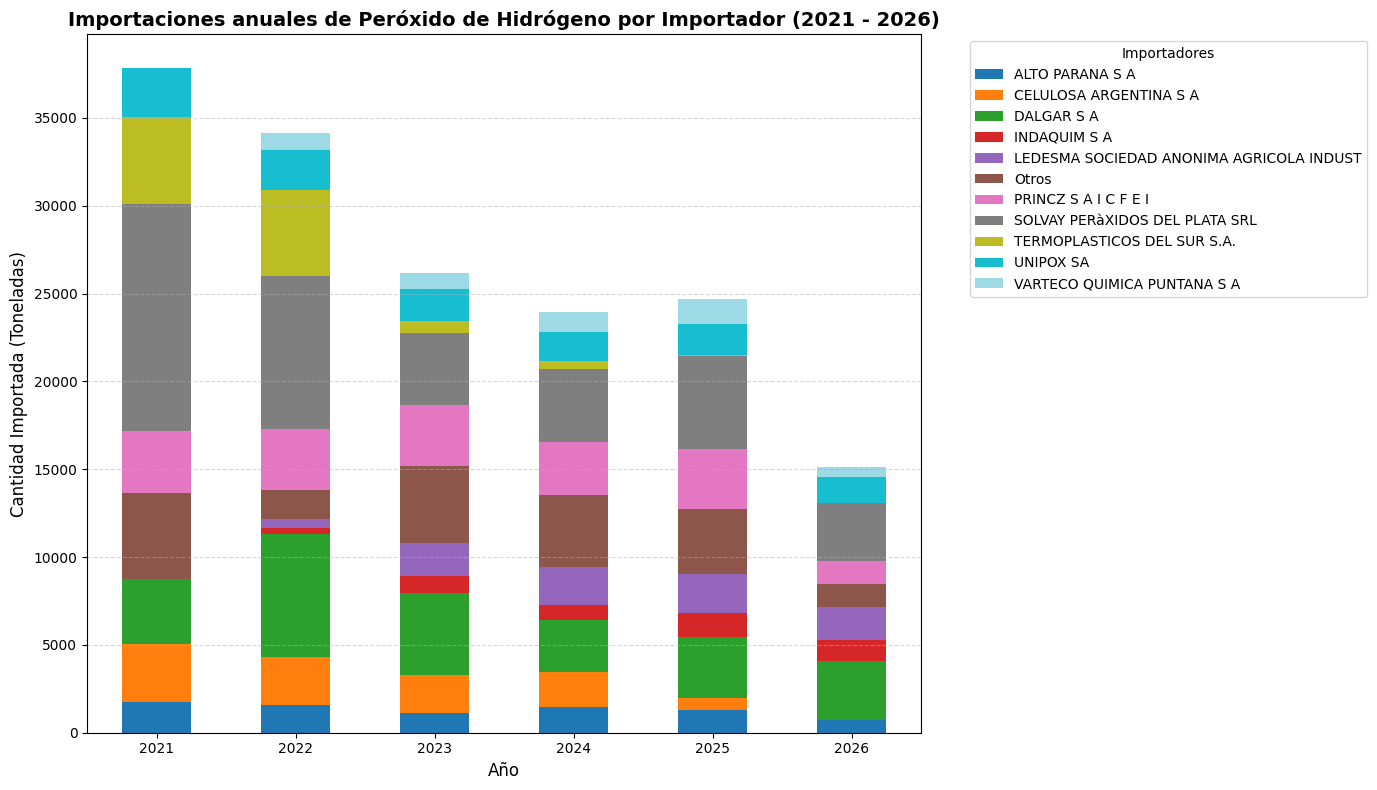

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Aseguramos extraer el año de la columna 'Date'
df['Anio'] = df['Date'].dt.year

# 2. Identificamos los importadores principales (por ejemplo, aquellos con > 2% del total global de importaciones)
volumen_total_por_importer = df.groupby('Importer')['Net Weight'].sum()
limite_volumen = 0.02 * volumen_total_por_importer.sum()
importers_principales = volumen_total_por_importer[volumen_total_por_importer >= limite_volumen].index

# Creamos una columna temporal con nombres simplificados
df['Importer_Simplificado'] = df['Importer'].apply(lambda x: x if x in importers_principales else 'Otros')

# 3. Agrupamos por Año e Importador Simplificado para sumar los Kilogramos ('Net Weight')
df_agrupado = df.groupby(['Anio', 'Importer_Simplificado'])['Net Weight'].sum().reset_index()

# Convertimos el peso neto a Toneladas (opcional, para que los números del eje Y sean más legibles)
df_agrupado['Toneladas'] = df_agrupado['Net Weight'] / 1000

# 4. Pivotamos la tabla para que los importadores sean las columnas y los años el índice
df_pivot = df_agrupado.pivot(index='Anio', columns='Importer_Simplificado', values='Toneladas').fillna(0)

# 5. Dibujamos el gráfico de barras apiladas
ax = df_pivot.plot(kind='bar', stacked=True, figsize=(14, 8), colormap='tab20')

plt.title("Importaciones anuales de Peróxido de Hidrógeno por Importador (2021 - 2026)", fontsize=14, fontweight='bold')
plt.xlabel("Año", fontsize=12)
plt.ylabel("Cantidad Importada (Toneladas)", fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Posicionamos la leyenda fuera del gráfico para que no tape las barras
plt.legend(title="Importadores", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

### Top 5 Importadores por Año (% del Total Anual) (Preguntas 1 y 2)

El siguiente código calcula la participación porcentual de cada empresa importadora sobre el total de kilogramos ingresados en cada año calendario, selecciona los 5 líderes de cada período y genera gráficos individuales por año.

/tmp/ipykernel_3020/1166351723.py:18: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  top5_por_anio = df_anual.groupby('Anio').apply(lambda x: x.nlargest(5, 'Porcentaje')).reset_index(drop=True)


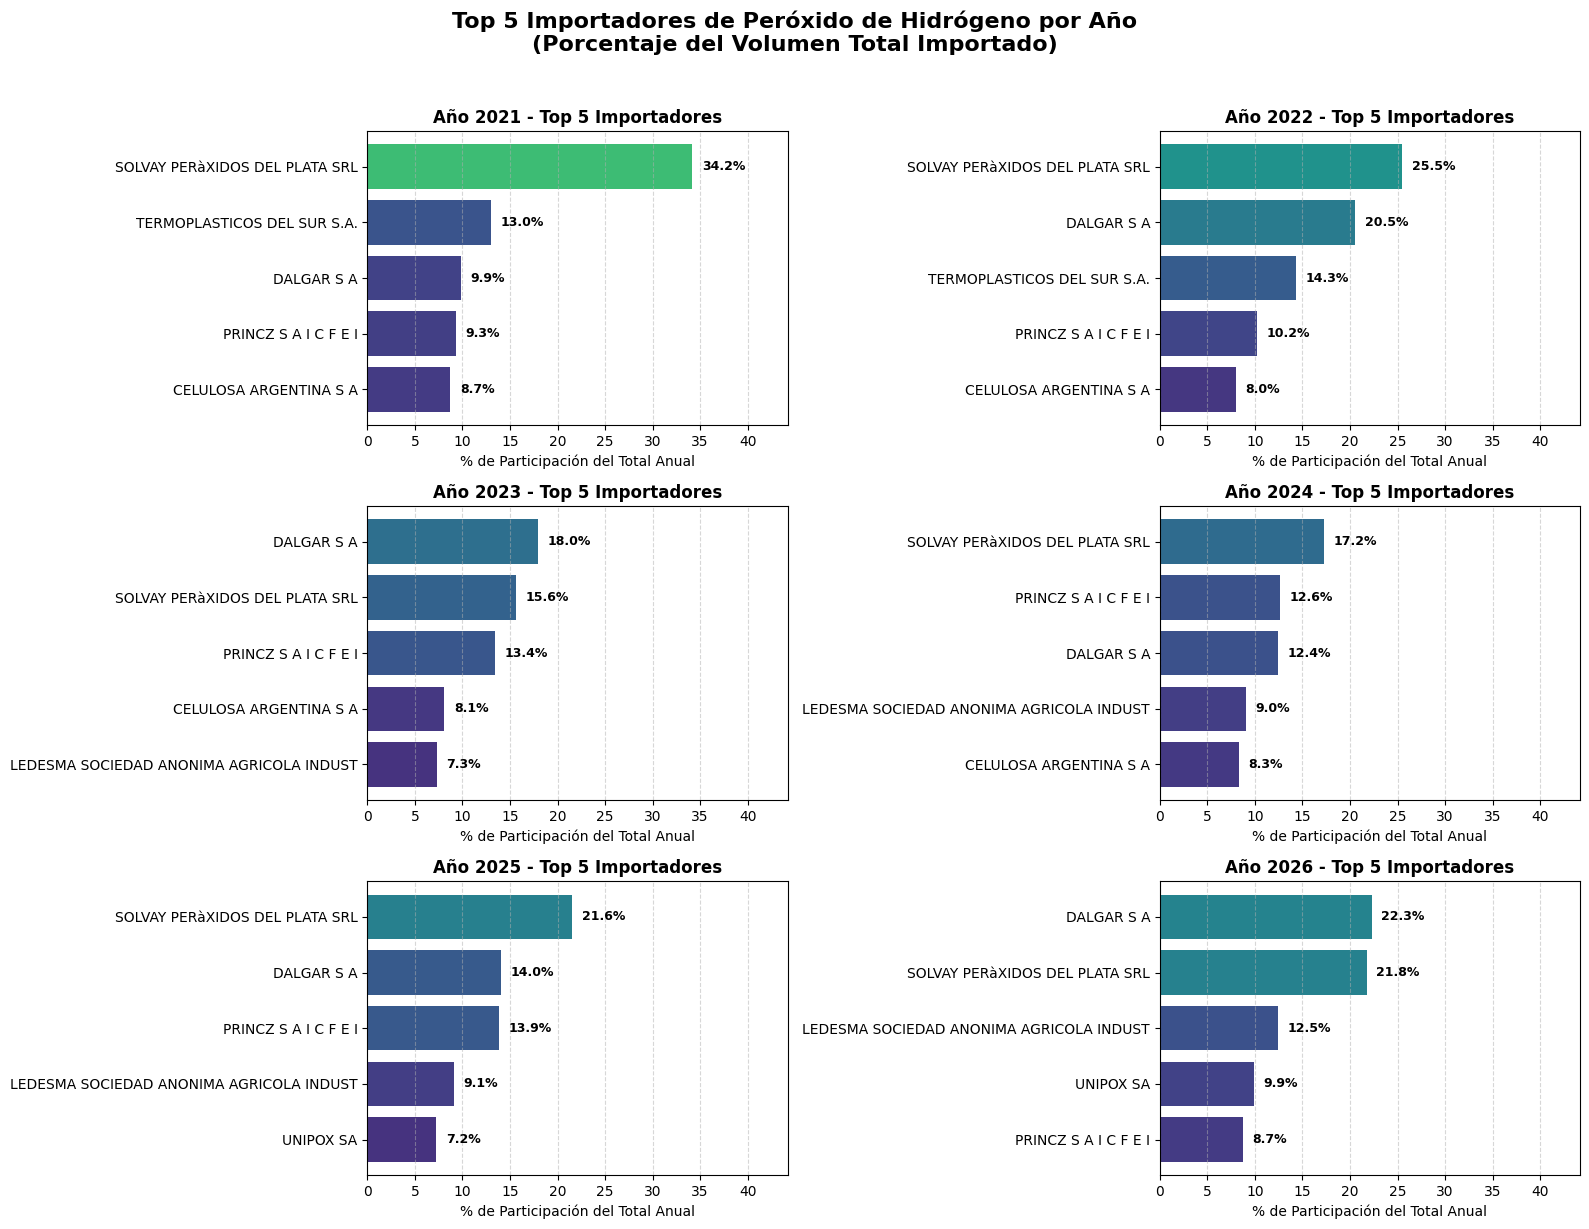

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Aseguramos que la columna 'Anio' esté en el DataFrame
if 'Anio' not in df.columns:
    df['Anio'] = df['Date'].dt.year

# 2. Agrupamos por Año e Importador para obtener la suma de peso neto
df_anual = df.groupby(['Anio', 'Importer'])['Net Weight'].sum().reset_index()

# 3. Calculamos el total anual para obtener el porcentaje
totales_anuales = df.groupby('Anio')['Net Weight'].sum().reset_index().rename(columns={'Net Weight': 'Total_Anio'})
df_anual = pd.merge(df_anual, totales_anuales, on='Anio')
df_anual['Porcentaje'] = (df_anual['Net Weight'] / df_anual['Total_Anio']) * 100

# 4. Filtramos los 5 más grandes de cada año
top5_por_anio = df_anual.groupby('Anio').apply(lambda x: x.nlargest(5, 'Porcentaje')).reset_index(drop=True)

# 5. Graficamos un subplot por cada año
anios_unicos = sorted(top5_por_anio['Anio'].unique())
num_anios = len(anios_unicos)

fig, axes = plt.subplots(nrows=(num_anios + 1) // 2, ncols=2, figsize=(16, 4 * ((num_anios + 1) // 2)))
axes = axes.flatten()

for i, anio in enumerate(anios_unicos):
    datos_anio = top5_por_anio[top5_por_anio['Anio'] == anio].sort_values(by='Porcentaje', ascending=True)
    ax = axes[i]

    # Usamos barras horizontales para que los nombres de las empresas se lean cómodamente
    bars = ax.barh(datos_anio['Importer'], datos_anio['Porcentaje'], color=plt.cm.viridis(datos_anio['Porcentaje'] / 50))

    ax.set_title(f"Año {anio} - Top 5 Importadores", fontsize=12, fontweight='bold')
    ax.set_xlabel("% de Participación del Total Anual")
    ax.set_xlim(0, max(top5_por_anio['Porcentaje']) + 10)
    ax.grid(axis='x', linestyle='--', alpha=0.5)

    # Añadimos las etiquetas de porcentaje al final de cada barra
    for bar in bars:
        width = bar.get_width()
        ax.text(width + 1, bar.get_y() + bar.get_height()/2, f'{width:.1f}%',
                va='center', ha='left', fontsize=9, fontweight='bold')

# Ocultamos subplots vacíos si el número de años es impar
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle("Top 5 Importadores de Peróxido de Hidrógeno por Año\n(Porcentaje del Volumen Total Importado)", fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

#Análisis de la evolución de los precios promedio y comparación de los precios de los principales importadores (Pregunta 3 y 5)

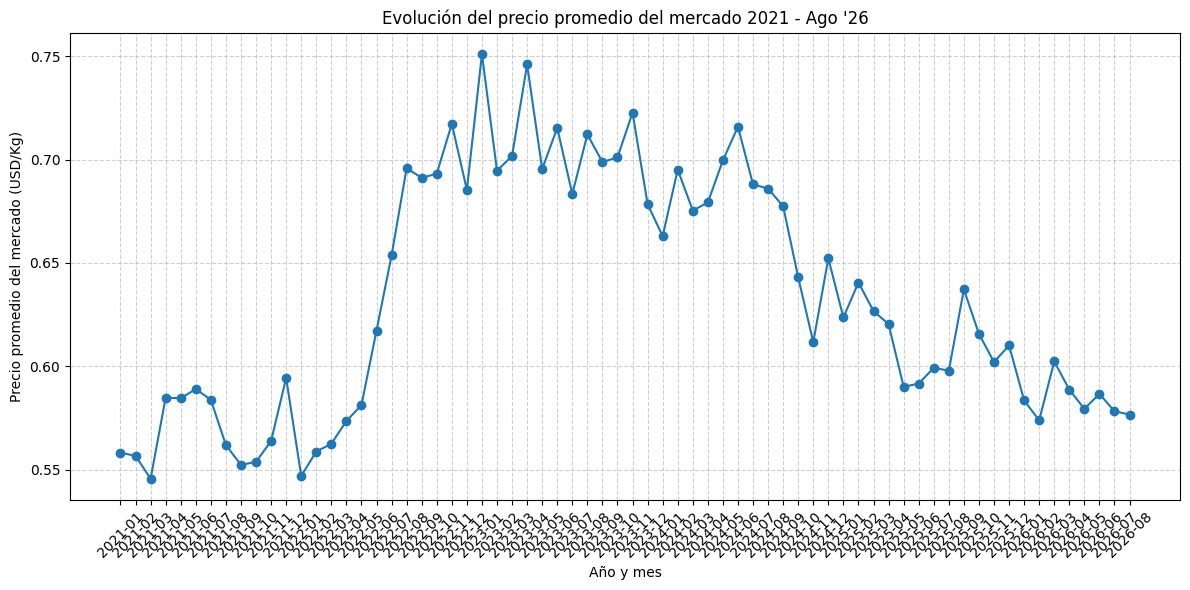

In [ ]:
import matplotlib.pyplot as plt

# 1. Creamos la columna 'anio_mes' en df para poder agrupar
df['anio_mes'] = df['Date'].dt.to_period('M').astype(str)

# 2. Creamos el DataFrame 'Imports_mes' calculando el promedio de 'Precio CIF USD/tn' (que representa Usd/kg)
Imports_mes = df.groupby('anio_mes')['Precio CIF USD/tn'].mean().reset_index()
Imports_mes.rename(columns={'Precio CIF USD/tn': 'Usd/kg'}, inplace=True)

# 3. Graficamos los datos agrupados
plt.figure(figsize=(12, 6))
plt.plot(Imports_mes["anio_mes"], Imports_mes["Usd/kg"], marker="o", linestyle="-")
plt.title("Evolución del precio promedio del mercado 2021 - Ago '26")
plt.xlabel("Año y mes")
plt.ylabel("Precio promedio del mercado (USD/Kg)")
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

Se observa que desde mitad de 2023 el precio del mercado desciende fuertemente por la caída de la actividad industrial (textil, papel) y por la apertura de importaciones

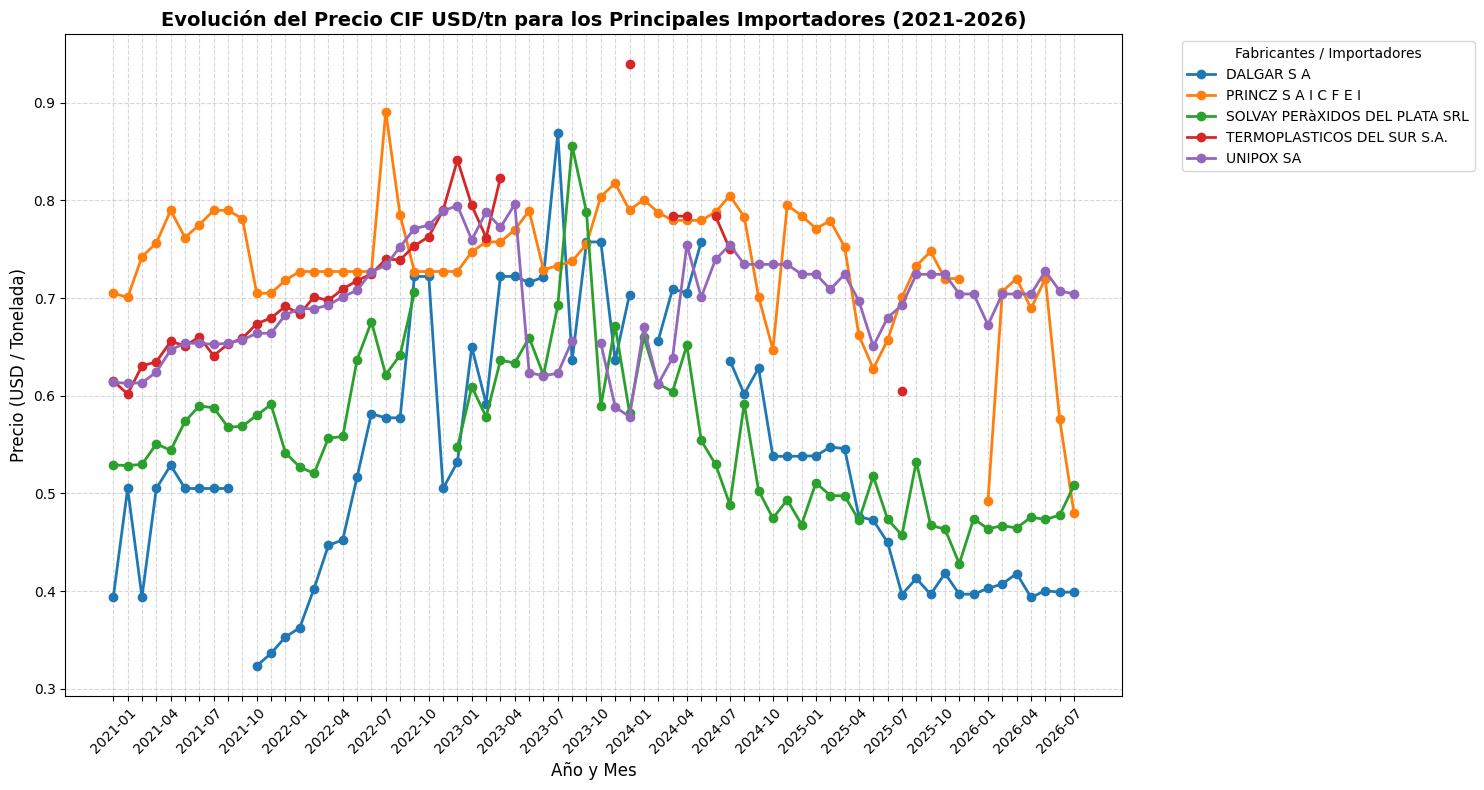

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Definimos los importadores más importantes para no saturar el gráfico (por ejemplo, el Top 5 histórico por volumen)
top_importers = df.groupby('Importer')['Net Weight'].sum().nlargest(5).index

# 2. Filtramos el DataFrame para quedarnos solo con estos top importadores
df_top = df[df['Importer'].isin(top_importers)].copy()

# 3. Agrupamos por Año-Mes e Importador para obtener el precio promedio (Precio CIF USD/tn)
# Nota: Usamos la columna 'anio_mes' que ya creaste en celdas anteriores
precios_evolucion = df_top.groupby(['anio_mes', 'Importer'])['Precio CIF USD/tn'].mean().unstack()
Fletes_evolucion = df_top.groupby(['anio_mes', 'Importer'])['Freight USD/tn'].mean().unstack()

# 4. Graficamos la evolución temporal
plt.figure(figsize=(15, 8))

for column in precios_evolucion.columns:
    plt.plot(precios_evolucion.index, precios_evolucion[column], marker='o', label=column, linewidth=2)

plt.title("Evolución del Precio CIF USD/tn para los Principales Importadores (2021-2026)", fontsize=14, fontweight='bold')
plt.xlabel("Año y Mes", fontsize=12)
plt.ylabel("Precio (USD / Tonelada)", fontsize=12)

# Ajustamos las etiquetas del eje X para que no se superpongan (mostramos cada 3 meses)
plt.xticks(rotation=45)
ax = plt.gca()
for ind, label in enumerate(ax.get_xticklabels()):
    if ind % 3 != 0:
        label.set_visible(False)

plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title="Fabricantes / Importadores", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

Los precios de competidor en azul son casi siempre menores por tener menor costo logístico ya que importa desde Uruguay en vez de Brasil (precios en verde, empresa en la que trabajo)

### Comparación Semestral de Precio vs. Flete por importador (Pregunta 4)

El siguiente gráfico agrupa las operaciones en semestres para los principales actores del mercado e ilustra el precio y costo de flete promedio

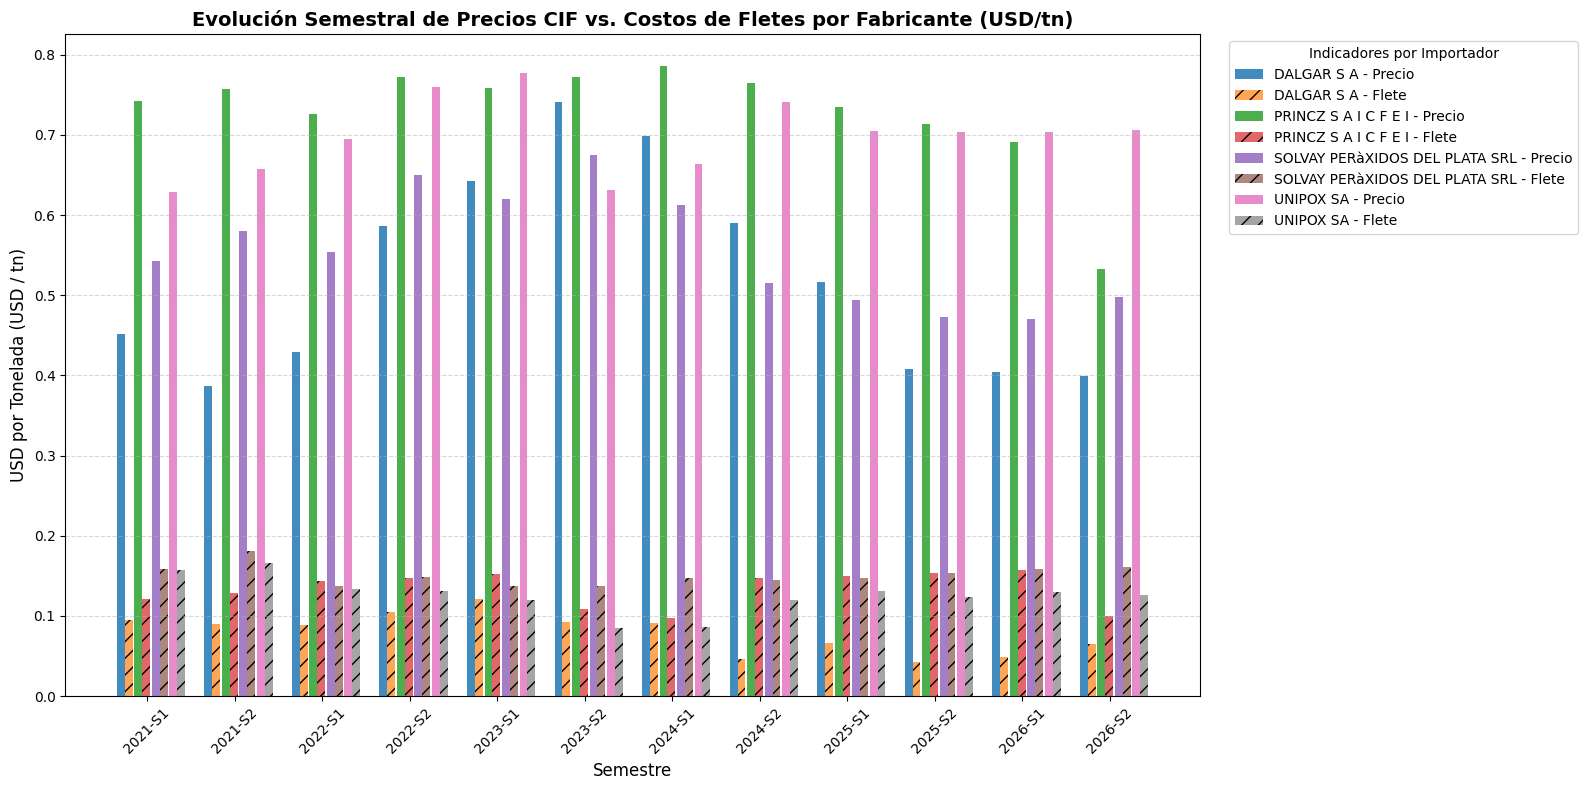

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Definimos los semestres agrupando por bloques de 6 meses (Ene-Jun = S1, Jul-Dic = S2)
df['Semestre'] = df['Date'].dt.year.astype(str) + '-' + df['Date'].dt.month.map(lambda m: 'S1' if m <= 6 else 'S2')

# 2. Seleccionamos el Top 4 de importadores para mantener la legibilidad visual del gráfico
top_importers_sem = df.groupby('Importer')['Net Weight'].sum().nlargest(4).index
df_sem = df[df['Importer'].isin(top_importers_sem)].copy()

# 3. Agrupamos y calculamos promedios
df_agrupado_sem = df_sem.groupby(['Semestre', 'Importer'])[['Precio CIF USD/tn', 'Freight USD/tn']].mean().reset_index()

# 4. Creamos la estructura del gráfico de barras
semestres_unicos = sorted(df_agrupado_sem['Semestre'].unique())
importers_unicos = df_agrupado_sem['Importer'].unique()

fig, ax = plt.subplots(figsize=(16, 8))

x = np.arange(len(semestres_unicos))
ancho_grupo = 0.8 / len(importers_unicos)  # Ancho total asignado para cada bloque semestral

# Dibujamos las barras agrupando por importador
for idx, importer in enumerate(importers_unicos):
    datos_imp = df_agrupado_sem[df_agrupado_sem['Importer'] == importer]
    # Alineamos los datos con los semestres existentes
    precios = [datos_imp[datos_imp['Semestre'] == s]['Precio CIF USD/tn'].values[0] if s in datos_imp['Semestre'].values else 0 for s in semestres_unicos]
    fletes = [datos_imp[datos_imp['Semestre'] == s]['Freight USD/tn'].values[0] if s in datos_imp['Semestre'].values else 0 for s in semestres_unicos]

    # Calculamos la desviación en el eje X para colocar las barras una al lado de la otra
    offset = (idx - len(importers_unicos)/2) * ancho_grupo + ancho_grupo/2

    # Graficamos el precio (barra sólida) y el flete (barra con trama/hachurado) para distinguir
    ax.bar(x + offset, precios, ancho_grupo * 0.45, label=f'{importer} - Precio', alpha=0.85)
    ax.bar(x + offset + (ancho_grupo * 0.45), fletes, ancho_grupo * 0.45, label=f'{importer} - Flete', hatch='//', alpha=0.7)

# 5. Formato y etiquetas
ax.set_title("Evolución Semestral de Precios CIF vs. Costos de Fletes por Fabricante (USD/tn)", fontsize=14, fontweight='bold')
ax.set_xlabel("Semestre", fontsize=12)
ax.set_ylabel("USD por Tonelada (USD / tn)", fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(semestres_unicos, rotation=45)
ax.grid(axis='y', linestyle='--', alpha=0.5)

# Leyenda y ordenamiento de elementos
ax.legend(title="Indicadores por Importador", bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=10)
plt.tight_layout()
plt.show()

In [ ]:
df.to_excel("MercadoPeroxlimpio.xlsx", index=False)
print("El dataset limpio se guardó como MercadoPeroxlimpio.xlsx")

El dataset limpio se guardó como MercadoPeroxlimpio.xlsx


Conclusiones del análisis dataset

El mercado argentino de agua oxigenada viene cayendo sin pausa desde 2023, lo que muestra una relación directa con la caída del consumo y la actividad industrial.
La incidencia de los fletes ha aumentado dado que los precios bajaron mientras los transportes se mantuvieron casi constantes desde 2021 en USD/tn.
Frente a este contexto se buscará importar producto desde Chile por la menor distancia respecto a Brasil.
Respecto al market share se mantiene relativamente constante, con un volumen de mercado menor para todos, lo que también explica la baja de precios.

